# Gojo 2020 Ependymoma — 04 · EMT-TF Expression

The EMT-TF step is **unconditional** (produced regardless of gate outcome) and is the last notebook. We score
a mesenchymal-TF panel — Snail/Zeb/Twist **plus** the FOXC and PRRX families (VIM is a marker, not a TF, and
is excluded) — gated on **detectable expression** (fraction expressing > 0.03), and overlay the two most
informative detectable factors as thresholded expressers on the grey manifold (house categorical style).

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 5378 | pseudotime range 0.0 -> 12.03


### Detection-gated EMT-TF panel

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:,j]; expr = x > 0; rho, p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\ndetectable TFs (frac>0.03): {ok.TF.tolist()}')
print(f'derived overlay pair: {early_tf} (earlier) <-> {late_tf} (terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC2      0.007       0.016      0.021     0.029 LATE(terminus)
TWIST1      0.090       0.279      0.345     0.066 LATE(terminus)
 FOXC1      0.095       0.249      0.423     0.068 LATE(terminus)
TWIST2      0.023       0.057      0.125     0.069 LATE(terminus)
 PRRX2      0.005       0.006      0.042     0.075 LATE(terminus)
 SNAI2      0.022       0.041      0.116     0.087 LATE(terminus)
 SNAI1      0.053       0.173      0.308     0.103 LATE(terminus)
  ZEB2      0.464       1.270      1.904     0.181 LATE(terminus)
 PRRX1      0.161       0.333      0.723     0.187 LATE(terminus)
  ZEB1      0.335       0.820      1.620     0.221 LATE(terminus)

detectable TFs (frac>0.03): ['TWIST1', 'FOXC1', 'SNAI1', 'ZEB2', 'PRRX1', 'ZEB1']
derived overlay pair: TWIST1 (earlier) <-> ZEB1 (terminus)


### Deliverable — `expression.pdf` (categorical thresholded-expresser overlay)

overlay thresholds (upper quartile among expressers): {'TWIST1': 4.413, 'ZEB1': 4.729} | cells shown: {'TWIST1': 121, 'ZEB1': 450}
TWIST1: 9.0% expressing; 121 shown (upper quartile), mean pseudotime of shown cells = 0.32 (all cells = 0.51)
ZEB1: 33.5% expressing; 450 shown (upper quartile), mean pseudotime of shown cells = 0.50 (all cells = 0.51)
saved expression.pdf


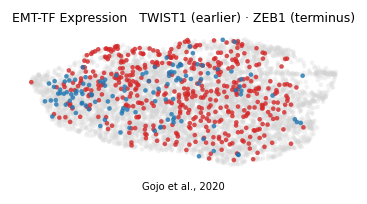

In [5]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (earlier) · {late_tf} (terminus)', size=7.5)
ax.text(.5, -.14, 'Gojo et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
print('saved expression.pdf')